Read data and create Train/Test split

In [46]:
#loading the clean data
import pandas as pd

books = pd.read_csv("../data/clean/books_clean.csv")
books.info()

<class 'pandas.DataFrame'>
RangeIndex: 175 entries, 0 to 174
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   book_id      175 non-null    int64  
 1   upc          175 non-null    str    
 2   title        175 non-null    str    
 3   category     175 non-null    str    
 4   description  174 non-null    str    
 5   lang         175 non-null    str    
 6   image_path   175 non-null    str    
 7   price        175 non-null    float64
 8   rating       175 non-null    int64  
 9   product_url  175 non-null    str    
dtypes: float64(1), int64(2), str(7)
memory usage: 13.8 KB


In [47]:
#split the data into train and test
from sklearn.model_selection import train_test_split
train_ids, test_ids = train_test_split(books["book_id"], test_size=0.2, random_state=42, stratify=books["category"])
print("Train:", len(train_ids))
print("Test:", len(test_ids))

Train: 140
Test: 35


In [48]:
#save the train/split data into a file
split_df = pd.DataFrame({
    "book_id": books["book_id"]
})

split_df["split"] = "train"

split_df.loc[split_df["book_id"].isin(test_ids), "split"] = "test"
split_df.to_csv("../data/features/split.csv",index=False)

display(split_df.head())

,book_id,split
0,998,train
1,958,train
2,954,train
3,946,train
4,939,train


Model Training

In [49]:
#read "features" and "split" file
features = pd.read_csv("../data/features/features_word_counts.csv")
split = pd.read_csv("../data/features/split.csv")

print(features.shape)
print(split.shape)

(175, 2116)
(175, 2)


In [50]:
#merge features, categoy and train/test type into one
df = features.merge(books[["book_id", "category"]], on="book_id", validate="one_to_one").merge(split, on="book_id", validate="one_to_one")

print(df.shape)
display(df[["book_id", "category", "split"]].head())

(175, 2118)


,book_id,category,split
0,998,Fiction,train
1,958,Fiction,train
2,954,Fiction,train
3,946,Fiction,train
4,939,Fiction,train


In [51]:
#create x_train, x_test, y_train, y_test
train = df[df["split"] == "train"]
test = df[df["split"] == "test"]

feature_columns = features.columns.drop("book_id")

X_train = train[feature_columns]
X_test = test[feature_columns]

y_train = train["category"]
y_test = test["category"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (140, 2115)
X_test: (35, 2115)
y_train: (140,)
y_test: (35,)


In [52]:
#Multinominal Naive Bayes
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

NB = MultinomialNB()
NB.fit(X_train, y_train)

Y_Pred_NB = NB.predict(X_test)

print("Accuracy:", accuracy_score(y_test, Y_Pred_NB))
print(confusion_matrix(y_test, Y_Pred_NB))
print(classification_report(y_test, Y_Pred_NB))

Accuracy: 0.8571428571428571
[[11  2]
 [ 3 19]]
              precision    recall  f1-score   support

     Fiction       0.79      0.85      0.81        13
  Nonfiction       0.90      0.86      0.88        22

    accuracy                           0.86        35
   macro avg       0.85      0.85      0.85        35
weighted avg       0.86      0.86      0.86        35



In [53]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression

LR = LogisticRegression(max_iter=1000)

LR.fit(X_train, y_train)

Y_Pred_LR = LR.predict(X_test)

print("Accuracy:", accuracy_score(y_test, Y_Pred_LR))
print(confusion_matrix(y_test, Y_Pred_LR))
print(classification_report(y_test, Y_Pred_LR))

Accuracy: 0.8
[[ 7  6]
 [ 1 21]]
              precision    recall  f1-score   support

     Fiction       0.88      0.54      0.67        13
  Nonfiction       0.78      0.95      0.86        22

    accuracy                           0.80        35
   macro avg       0.83      0.75      0.76        35
weighted avg       0.81      0.80      0.79        35



In [54]:
#Read TF-IDF
tfidf = pd.read_csv("../data/features/features_tfidf.csv")

df_tfidf = tfidf.merge(books[["book_id", "category"]], on="book_id", validate="one_to_one").merge(split, on="book_id", validate="one_to_one")

print(tfidf.shape)
display(tfidf.head())

(175, 2116)


,book_id,000,10,100,11,13,1942,1945,1950s,1955,...,wrote,wry,year,years,yes,york,young,younger,youngest,youth
0,998,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
1,958,0.0,0.090247,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00000,0.0,0.0,0.0,0.054418,0.0,0.0,0.0
2,954,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.08613,0.0,0.0,0.0,0.077598,0.0,0.0,0.0
3,946,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
4,939,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0


In [55]:
#Create x_train, x_test, y_train, y_test for TF-IDF
train_tfidf = df_tfidf[df_tfidf["split"] == "train"]
test_tfidf = df_tfidf[df_tfidf["split"] == "test"]

feature_columns_tfidf = tfidf.columns.drop("book_id")

X_train_tfidf = train_tfidf[feature_columns_tfidf]
X_test_tfidf = test_tfidf[feature_columns_tfidf]

y_train_tfidf = train_tfidf["category"]
y_test_tfidf = test_tfidf["category"]

print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

(140, 2115)
(35, 2115)


In [56]:
#Logistic Regression with TF-IDF
LR_tfidf = LogisticRegression(max_iter=1000)

LR_tfidf.fit(X_train_tfidf, y_train_tfidf)

Y_Pred_LR_tfidf = LR_tfidf.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test_tfidf, Y_Pred_LR_tfidf))

print(confusion_matrix(y_test_tfidf, Y_Pred_LR_tfidf))

print(classification_report(y_test_tfidf, Y_Pred_LR_tfidf))

Accuracy: 0.6571428571428571
[[ 1 12]
 [ 0 22]]
              precision    recall  f1-score   support

     Fiction       1.00      0.08      0.14        13
  Nonfiction       0.65      1.00      0.79        22

    accuracy                           0.66        35
   macro avg       0.82      0.54      0.46        35
weighted avg       0.78      0.66      0.55        35



Model Evaluation

Using three models, we can see that Naive Bayes has the highest accuracy, so I will evaluate model that use Naive Bayes below

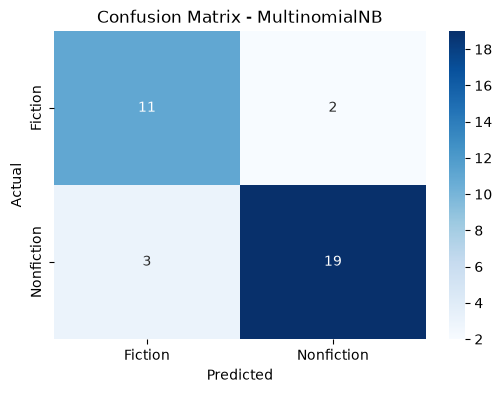

In [57]:
#draw confusion matrix and save into a file
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

labels = ["Fiction", "Nonfiction"]

cm = confusion_matrix(y_test, Y_Pred_NB, labels=labels)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - MultinomialNB")

plt.savefig("../results/confusion_matrix.png", dpi=300, bbox_inches="tight")

plt.show()

In [58]:
#save the accuracy results into a file
results = pd.DataFrame({
    "Model": [
        "MultinomialNB + Word Counts",
        "Logistic Regression + Word Counts",
        "Logistic Regression + TF-IDF"
    ],
    "Accuracy": [
        accuracy_score(y_test, Y_Pred_NB),
        accuracy_score(y_test, Y_Pred_LR),
        accuracy_score(y_test_tfidf, Y_Pred_LR_tfidf)
    ]
})

display(results)

results.to_csv("../results/model_comparison.csv", index=False)

,Model,Accuracy
0,MultinomialNB + Word Counts,0.857143
1,Logistic Regression + Word Counts,0.800000
2,Logistic Regression + TF-IDF,0.657143
